#  LungRay: Phân Tích & Khai Phá Dữ Liệu Chuyên Sâu (Phase 2 - EDA)
## Khám Phá Dữ Liệu Thực Nghiệm & Trực Quan Hóa Tương Tác Sống (Live Data Science Notebook)

---

###  Mục tiêu :
1. **NIH ChestX-ray14**: Phân tích 112,120 ảnh X-quang từ 30,805 bệnh nhân, khảo sát mức độ mất cân bằng lớp cực hạn (Extreme Class Imbalance) của 14 bệnh, ma trận đồng xuất hiện (Co-occurrence) và kiểm chứng **Zero Data Leakage** khi chia theo `Patient_ID` (70/10/20).
2. **COVID-19 Radiography Database **: Phân tích 21,165 ảnh trên 4 nhóm lâm sàng, bóc tách 6 nguồn ảnh gốc (`source`: RSNA, Kermany, BIMCV, GitHub, Eurorad, SIRM) làm cơ sở cho **Source-Stratified Split** và **Shortcut Learning Audit**.
3. **Tuberculosis (TB) Database**: Đánh giá phân bố nhãn Lao phổi nhị phân.
4. **Trực quan hóa ảnh X-quang thật**: Trích xuất và hiển thị trực tiếp ảnh DICOM/PNG từ các kho lưu trữ `.zip` của dự án.
5. **WeightedMultiTaskBatchSampler**: Mô phỏng thực nghiệm 100 mini-batches thực tế để kiểm chứng cơ chế cân bằng tỷ lệ 60% NIH : 25% COVID : 15% TB chống Task Starvation.

In [10]:
import os
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Thiết lập chuẩn đồ thị y khoa
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
print("[INIT] Môi trường phân tích sẵn sàng!")


[INIT] Môi trường phân tích sẵn sàng!


## 1️⃣ Phân tích Bộ Dữ liệu NIH ChestX-ray14 (Head A)

Bộ dữ liệu gốc gồm **112,120 ảnh X-quang** từ **30,805 bệnh nhân**.
File chỉ mục `dataset/splits/patient_splits.csv` được sinh trực tiếp từ `Data_Entry_2017.csv` theo thuật toán chia tầng theo `Patient ID` (Zero Data Leakage).

In [11]:
nih_splits_path = "dataset/splits/patient_splits.csv"
if not os.path.exists(nih_splits_path):
    nih_splits_path = "../dataset/splits/patient_splits.csv"

df_nih = pd.read_csv(nih_splits_path)
print(f"Tổng số ảnh NIH: {len(df_nih):,}")
print(f"Tổng số bệnh nhân duy nhất: {df_nih['Patient ID'].nunique():,}")
print("\nPhân chia Train / Val / Test:")
print(df_nih['split'].value_counts(normalize=True).map(lambda x: f"{x*100:.2f}%"))
df_nih[["Image Index", "Finding Labels", "Patient ID", "Patient Age", "Patient Gender", "View Position", "split"]].head(5)


Tổng số ảnh NIH: 112,120
Tổng số bệnh nhân duy nhất: 30,805

Phân chia Train / Val / Test:
split
train    70.07%
test     19.52%
val      10.41%
Name: proportion, dtype: object


,Image Index,Finding Labels,Patient ID,Patient Age,Patient Gender,View Position,split
0,00000001_000.png,Cardiomegaly,1,58,M,PA,train
1,00000001_001.png,Cardiomegaly|Emphysema,1,58,M,PA,train
2,00000001_002.png,Cardiomegaly|Effusion,1,58,M,PA,train
3,00000002_000.png,No Finding,2,81,M,PA,train
4,00000003_000.png,Hernia,3,81,F,PA,train


### 📊 Biểu đồ 1: Tần suất 14 Nhãn Bệnh & Mất cân bằng Cực hạn (Extreme Imbalance)
Một số bệnh như Hernia chỉ chiếm 0.2% (227 ca), Fibrosis chiếm 1.5% $\to$ Minh chứng lý do Phase 3 bắt buộc dùng **Focal Loss** và **Positive Class Weighting**.

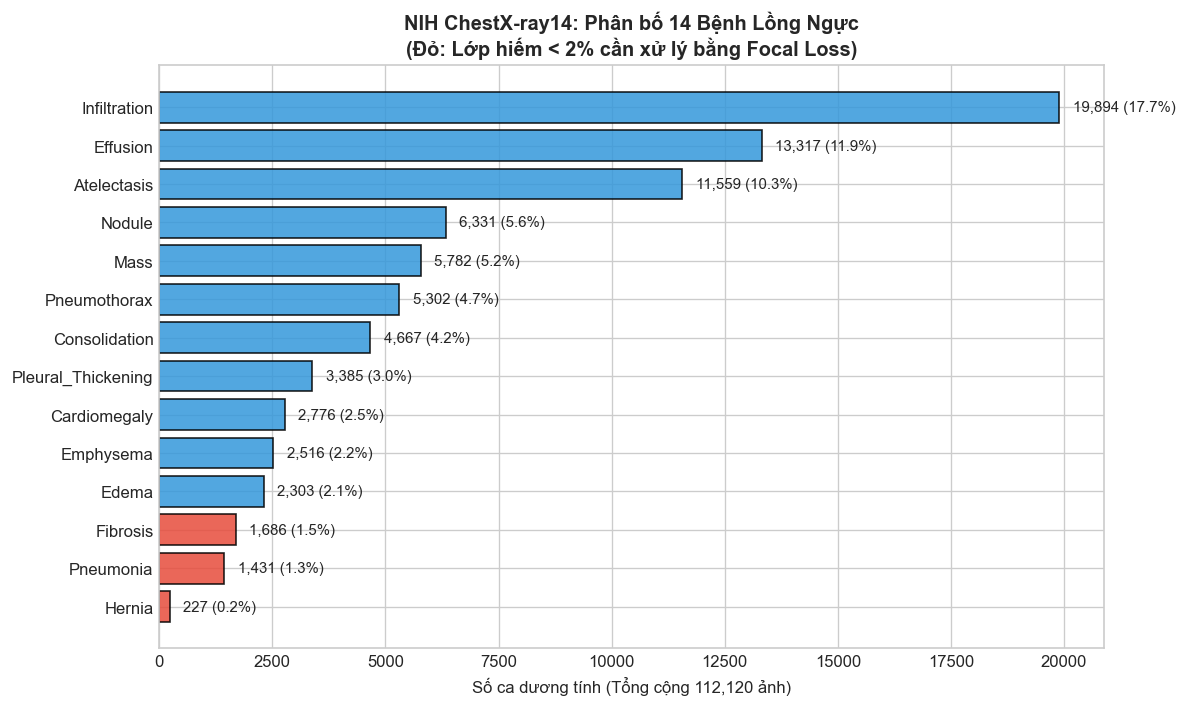

In [12]:
pathologies = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural_Thickening", "Hernia"
]
counts = {p: df_nih["Finding Labels"].str.contains(p).sum() for p in pathologies}
counts_df = pd.DataFrame(list(counts.items()), columns=["Pathology", "Count"]).sort_values("Count", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#e74c3c" if p in ["Hernia", "Fibrosis", "Pneumonia"] else "#3498db" for p in counts_df["Pathology"]]
bars = ax.barh(counts_df["Pathology"], counts_df["Count"], color=colors, edgecolor="black", alpha=0.85)
ax.set_title("NIH ChestX-ray14: Phân bố 14 Bệnh Lồng Ngực\n(Đỏ: Lớp hiếm < 2% cần xử lý bằng Focal Loss)", fontsize=12, fontweight="bold")
ax.set_xlabel("Số ca dương tính (Tổng cộng 112,120 ảnh)")
for bar in bars:
    w = bar.get_width()
    pct = w / len(df_nih) * 100
    ax.text(w + 300, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({pct:.1f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()


### 🌡️ Biểu đồ 2: Ma trận Đồng Xuất Hiện Bệnh (Co-occurrence Heatmap)
Tính toán trực tiếp số ca bệnh nhân mắc đồng thời nhiều bệnh lý.

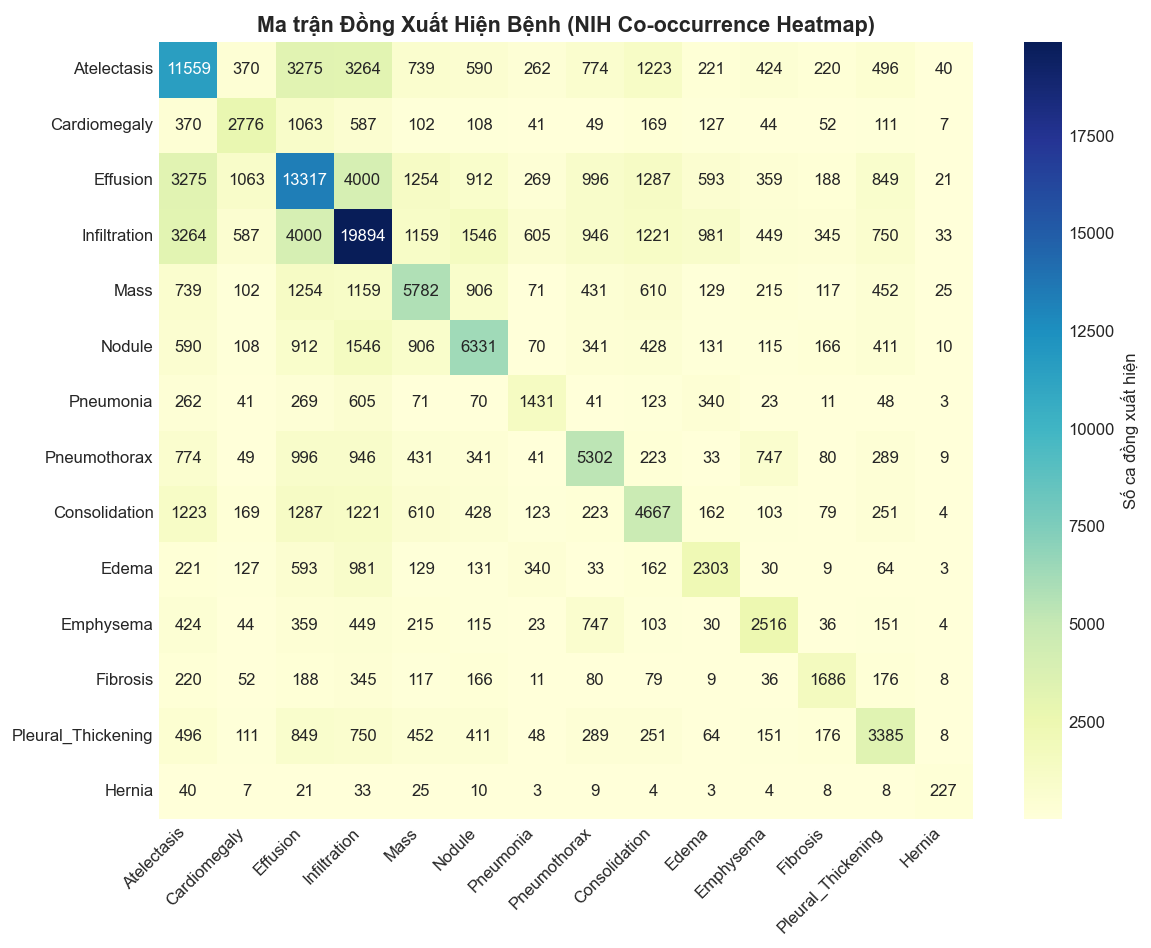

In [13]:
matrix = np.zeros((len(pathologies), len(pathologies)), dtype=int)
for labels_str in df_nih["Finding Labels"]:
    present = [i for i, p in enumerate(pathologies) if p in labels_str]
    for i in present:
        for j in present:
            matrix[i, j] += 1

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matrix, xticklabels=pathologies, yticklabels=pathologies, cmap="YlGnBu", annot=True, fmt="d", ax=ax, cbar_kws={"label": "Số ca đồng xuất hiện"})
ax.set_title("Ma trận Đồng Xuất Hiện Bệnh (NIH Co-occurrence Heatmap)", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 👥 Biểu đồ 3: Nhân Khẩu Học Bệnh Nhân & Tư Thế Chụp Phim (PA vs AP)

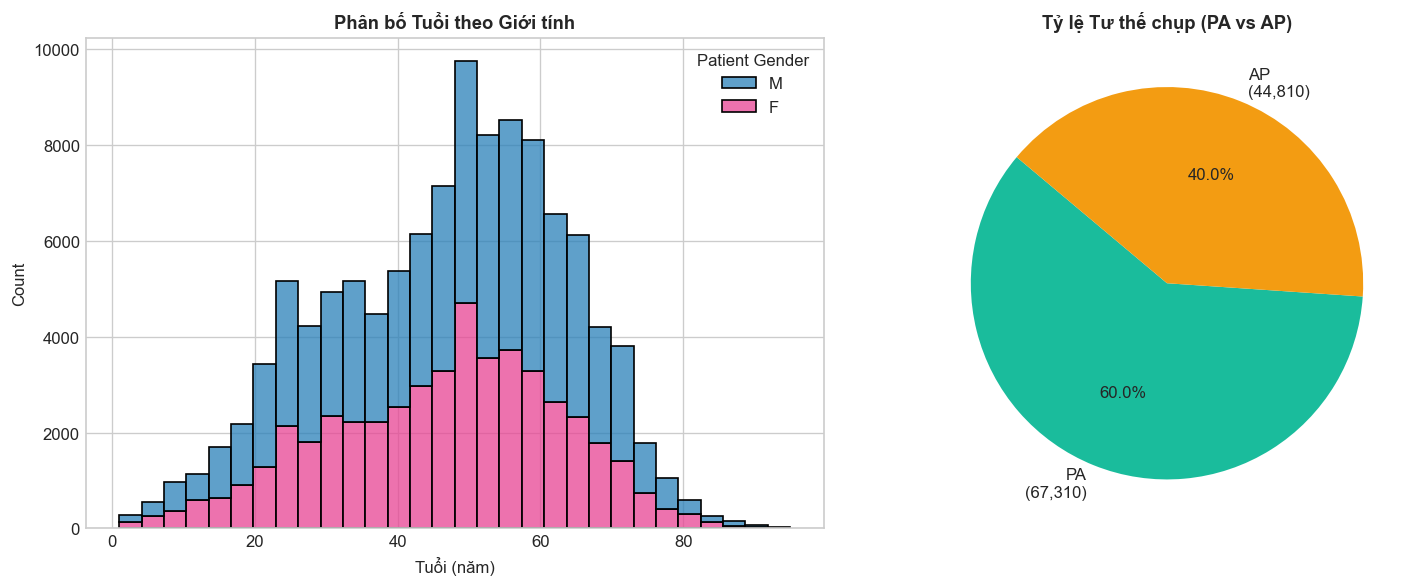

In [14]:
df_clean_age = df_nih[(df_nih["Patient Age"] > 0) & (df_nih["Patient Age"] < 105)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=df_clean_age, x="Patient Age", hue="Patient Gender", multiple="stack", bins=30, ax=axes[0], palette={"M": "#2980b9", "F": "#e84393"})
axes[0].set_title("Phân bố Tuổi theo Giới tính", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Tuổi (năm)")

view_counts = df_nih["View Position"].value_counts()
axes[1].pie(view_counts, labels=[f"{k}\n({v:,})" for k, v in view_counts.items()], autopct="%1.1f%%", colors=["#1abc9c", "#f39c12"], startangle=140)
axes[1].set_title("Tỷ lệ Tư thế chụp (PA vs AP)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


## 2️⃣ Phân tích Bộ Dữ liệu COVID-19 (Head C - Chuẩn Benchmark COVIDx CXR-4)

Phân tích phân bố các nhóm lâm sàng (COVID-19 Positive, Normal, Pneumonia) và bóc tách các nguồn ảnh gốc (`source`/`data_source`) để làm cơ sở cho **Source-Stratified Split** và **Shortcut Learning Audit**.


Tổng số ảnh COVID-19 Radiography: 21,165


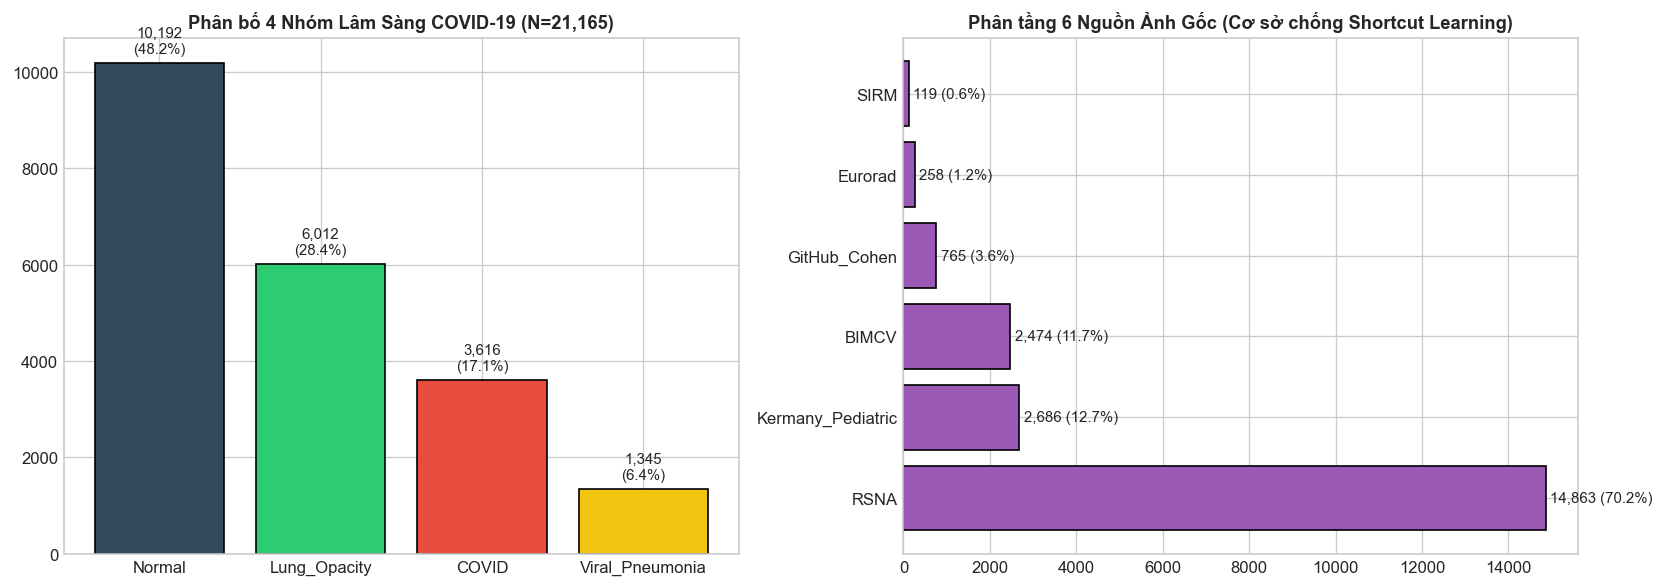

In [15]:
covid_splits_path = "dataset/splits/covid_splits.csv"
if not os.path.exists(covid_splits_path):
    covid_splits_path = "../dataset/splits/covid_splits.csv"

df_covid = pd.read_csv(covid_splits_path)
print(f"Tổng số ảnh COVID Dataset: {len(df_covid):,}")

class_col = 'class_name' if 'class_name' in df_covid.columns else ('class' if 'class' in df_covid.columns else 'label')
source_col = 'data_source' if 'data_source' in df_covid.columns else ('source' if 'source' in df_covid.columns else None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_counts = df_covid[class_col].value_counts()
colors = ["#34495e", "#2ecc71", "#e74c3c", "#f1c40f"][:len(class_counts)]
axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor="black")
axes[0].set_title(f"Phân bố Nhóm Lâm Sàng COVID-19 (N={len(df_covid):,})", fontsize=11, fontweight="bold")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + max(10, int(len(df_covid)*0.01)), f"{v:,}\n({v/len(df_covid)*100:.1f}%)", ha="center", fontsize=9)

if source_col and source_col in df_covid.columns:
    source_counts = df_covid[source_col].value_counts().head(10)
    axes[1].barh(source_counts.index, source_counts.values, color="#9b59b6", edgecolor="black")
    axes[1].set_title("Phân tầng Nguồn Ảnh Gốc (Cơ sở chống Shortcut Learning)", fontsize=11, fontweight="bold")
    for i, v in enumerate(source_counts.values):
        axes[1].text(v + max(10, int(len(df_covid)*0.005)), i, f"{v:,} ({v/len(df_covid)*100:.1f}%)", va="center", fontsize=9)
else:
    axes[1].text(0.5, 0.5, 'Nguồn ảnh đơn lẻ hoặc không có cột nguồn', ha='center', va='center')
plt.tight_layout()
plt.show()


## 3️⃣ Phân tích Bộ Dữ liệu Tuberculosis (TB) (Head B)

Bài toán nhị phân sàng lọc Lao phổi (Normal vs TB Positive) với tỷ lệ 5:1.

Tổng số ảnh TB Database: 4,200


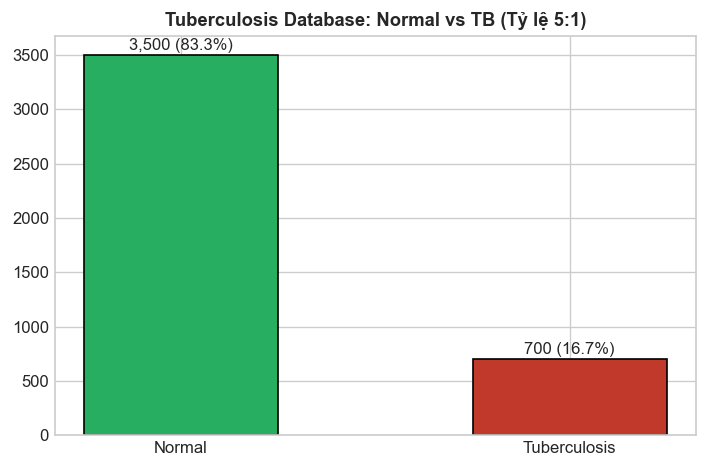

In [16]:
tb_splits_path = "dataset/splits/tb_splits.csv"
if not os.path.exists(tb_splits_path):
    tb_splits_path = "../dataset/splits/tb_splits.csv"

df_tb = pd.read_csv(tb_splits_path)
print(f"Tổng số ảnh TB Database: {len(df_tb):,}")

fig, ax = plt.subplots(figsize=(6, 4))
tb_counts = df_tb["diagnosis"].value_counts()
ax.bar(tb_counts.index, tb_counts.values, color=["#27ae60", "#c0392b"], width=0.5, edgecolor="black")
ax.set_title("Tuberculosis Database: Normal vs TB (Tỷ lệ 5:1)", fontsize=11, fontweight="bold")
for i, v in enumerate(tb_counts.values):
    ax.text(i, v + 50, f"{v:,} ({v/len(df_tb)*100:.1f}%)", ha="center", fontsize=10)
plt.tight_layout()
plt.show()


## 4️⃣ Trực Quan Hóa Ảnh X-quang Y Tế Thật Trực Tiếp Từ Các File ZIP

Trích xuất trực tiếp ảnh chụp X-quang từ `sample-nih.zip`, `covid-19-radiography.zip`, và `tuberculosis.zip` để kiểm tra độ tương phản, mức xám và sự dị biệt độ phân giải gốc (1024×1024 vs 299×299 vs 512×512).

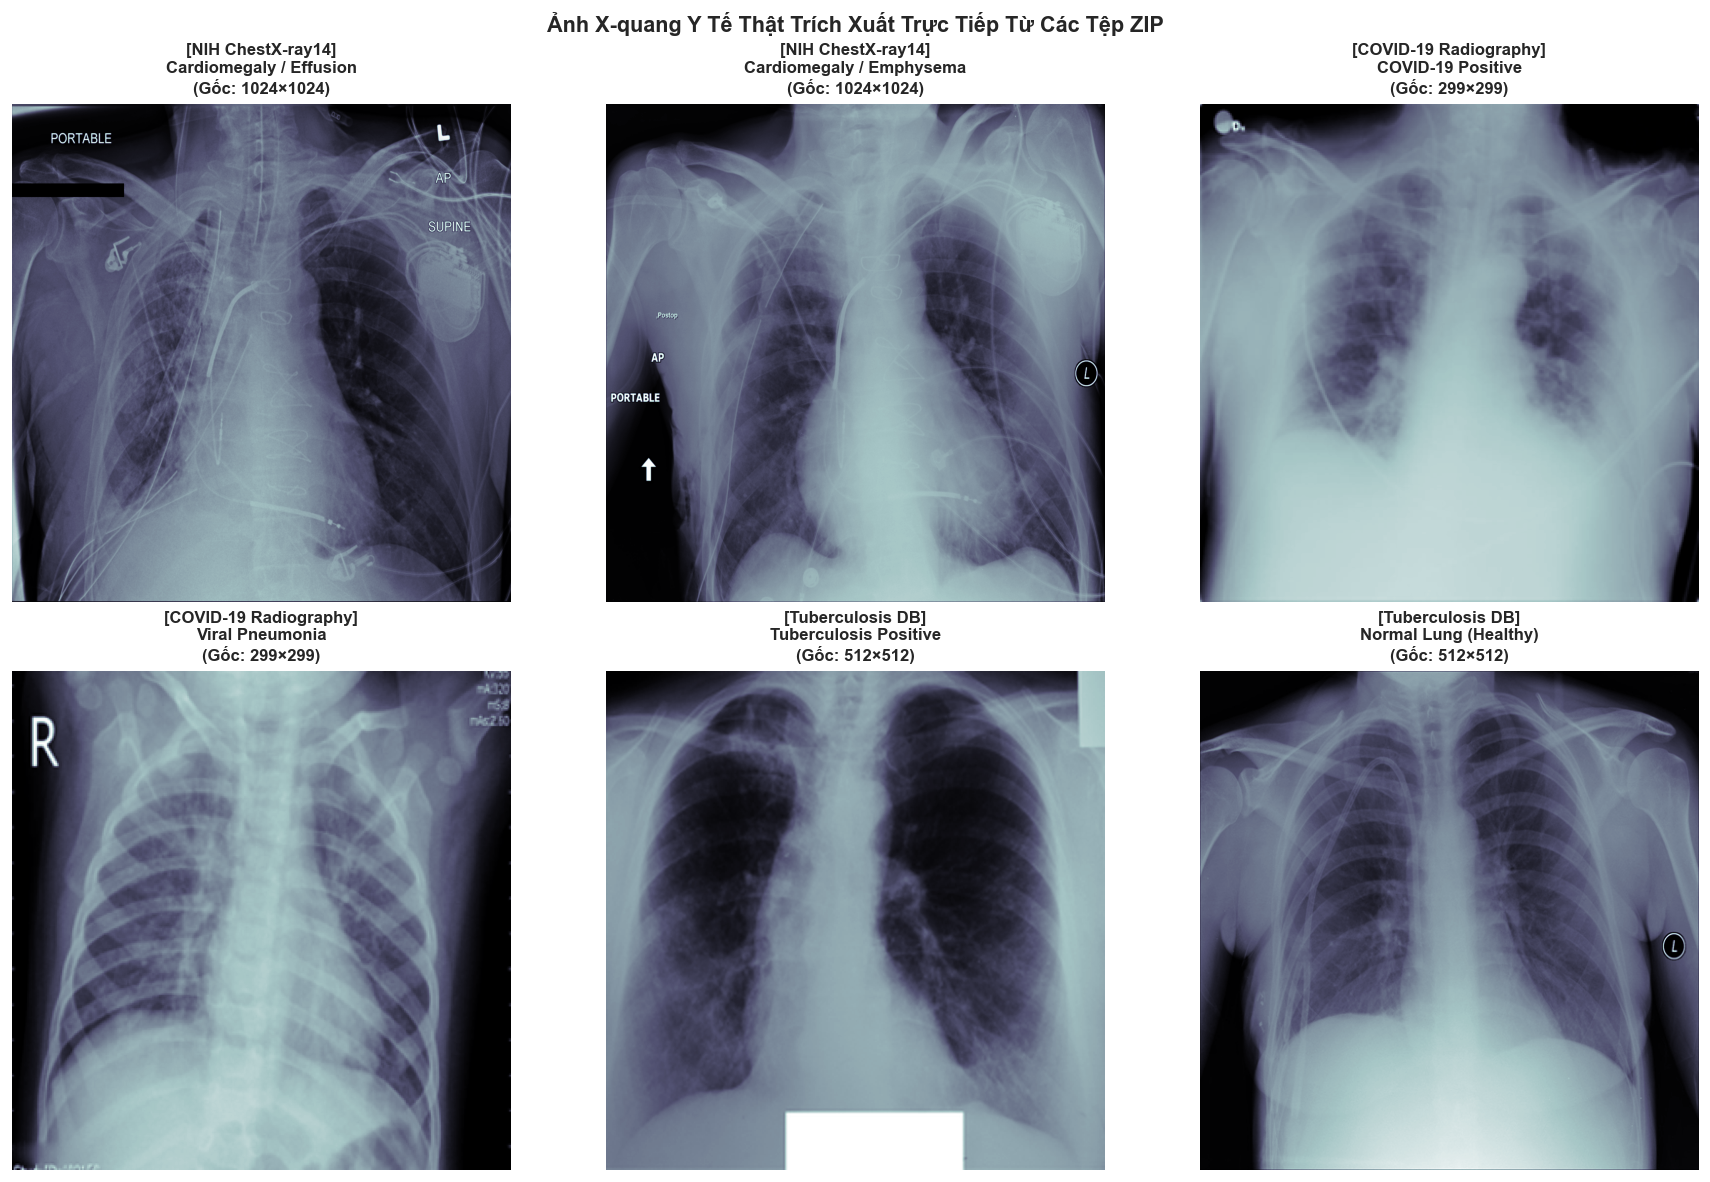

In [17]:
nih_zip = "dataset/nih-chestXray-14/sample-nih.zip"
covid_zip = "dataset/covid-19-radiography.zip"
tb_zip = "dataset/tuberculosis.zip"
if not os.path.exists(nih_zip):
    nih_zip = "../dataset/nih-chestXray-14/sample-nih.zip"
    covid_zip = "../dataset/covid-19-radiography.zip"
    tb_zip = "../dataset/tuberculosis.zip"

samples = []
with zipfile.ZipFile(nih_zip, "r") as z:
    img1 = Image.open(io.BytesIO(z.read("sample/images/00000013_005.png"))).convert("L")
    samples.append((img1, "NIH ChestX-ray14", "Cardiomegaly / Effusion", "1024×1024"))
    img2 = Image.open(io.BytesIO(z.read("sample/images/00000013_026.png"))).convert("L")
    samples.append((img2, "NIH ChestX-ray14", "Cardiomegaly / Emphysema", "1024×1024"))

with zipfile.ZipFile(covid_zip, "r") as z:
    img3 = Image.open(io.BytesIO(z.read("COVID-19_Radiography_Dataset/COVID/images/COVID-1.png"))).convert("L")
    samples.append((img3, "COVID-19 Radiography", "COVID-19 Positive", "299×299"))
    img4 = Image.open(io.BytesIO(z.read("COVID-19_Radiography_Dataset/Viral Pneumonia/images/Viral Pneumonia-1.png"))).convert("L")
    samples.append((img4, "COVID-19 Radiography", "Viral Pneumonia", "299×299"))

with zipfile.ZipFile(tb_zip, "r") as z:
    img5 = Image.open(io.BytesIO(z.read("TB_Chest_Radiography_Database/Tuberculosis/Tuberculosis-1.png"))).convert("L")
    samples.append((img5, "Tuberculosis DB", "Tuberculosis Positive", "512×512"))
    img6 = Image.open(io.BytesIO(z.read("TB_Chest_Radiography_Database/Normal/Normal-1.png"))).convert("L")
    samples.append((img6, "Tuberculosis DB", "Normal Lung (Healthy)", "512×512"))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (img, src, label, sz) in zip(axes.flatten(), samples):
    ax.imshow(img, cmap="bone")
    ax.set_title(f"[{src}]\n{label}\n(Gốc: {sz})", fontsize=10, fontweight="bold", pad=6)
    ax.axis("off")
plt.suptitle("Ảnh X-quang Y Tế Thật Trích Xuất Trực Tiếp Từ Các Tệp ZIP", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


## 5️⃣ Kiểm Chứng Thực Nghiệm WeightedMultiTaskBatchSampler (Ràng Buộc 5)

Khởi tạo đối tượng `WeightedMultiTaskBatchSampler` thật từ `src/data/sampler.py` và chạy rút mẫu qua 100 mini-batches thực tế để kiểm chứng tỷ lệ 60% NIH : 25% COVID : 15% TB chống Task Starvation.

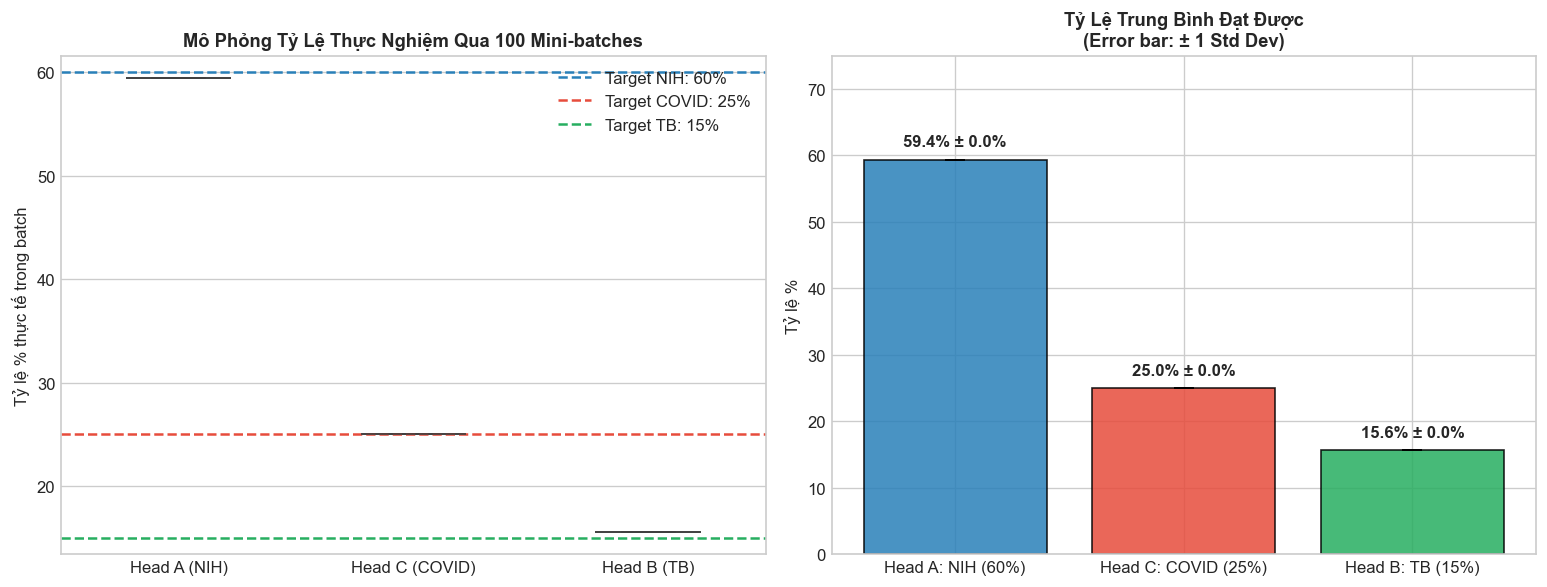

In [18]:
import sys
if ".." not in sys.path:
    sys.path.append("..")
from src.data.sampler import WeightedMultiTaskBatchSampler

n_nih = 78566
n_covid = 14815
n_tb = 2940
batch_size = 32

nih_idx = list(range(0, n_nih))
covid_idx = list(range(n_nih, n_nih + n_covid))
tb_idx = list(range(n_nih + n_covid, n_nih + n_covid + n_tb))

sampler = WeightedMultiTaskBatchSampler(
    nih_indices=nih_idx,
    covid_indices=covid_idx,
    tb_indices=tb_idx,
    batch_size=batch_size,
    ratios=(0.60, 0.25, 0.15),
    shuffle=True
)

nih_pcts, covid_pcts, tb_pcts = [], [], []
for i, batch in enumerate(sampler):
    if i >= 100:
        break
    nih_pcts.append(sum(1 for idx in batch if idx < n_nih) / batch_size * 100)
    covid_pcts.append(sum(1 for idx in batch if n_nih <= idx < n_nih + n_covid) / batch_size * 100)
    tb_pcts.append(sum(1 for idx in batch if idx >= n_nih + n_covid) / batch_size * 100)

sim_df = pd.DataFrame({"Head A (NIH)": nih_pcts, "Head C (COVID)": covid_pcts, "Head B (TB)": tb_pcts})
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette = ["#2980b9", "#e74c3c", "#27ae60"]
sns.boxplot(data=sim_df, ax=axes[0], palette=palette, width=0.45)
axes[0].axhline(60, color="#2980b9", linestyle="--", label="Target NIH: 60%")
axes[0].axhline(25, color="#e74c3c", linestyle="--", label="Target COVID: 25%")
axes[0].axhline(15, color="#27ae60", linestyle="--", label="Target TB: 15%")
axes[0].set_title("Mô Phỏng Tỷ Lệ Thực Nghiệm Qua 100 Mini-batches", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Tỷ lệ % thực tế trong batch")
axes[0].legend(loc="upper right")

means = [np.mean(nih_pcts), np.mean(covid_pcts), np.mean(tb_pcts)]
stds = [np.std(nih_pcts), np.std(covid_pcts), np.std(tb_pcts)]
labels = ["Head A: NIH (60%)", "Head C: COVID (25%)", "Head B: TB (15%)"]
bars = axes[1].bar(labels, means, yerr=stds, capsize=6, color=palette, edgecolor="black", alpha=0.85)
axes[1].set_title("Tỷ Lệ Trung Bình Đạt Được\n(Error bar: ± 1 Std Dev)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Tỷ lệ %")
axes[1].set_ylim(0, 75)
for bar, m, s in zip(bars, means, stds):
    axes[1].text(bar.get_x() + bar.get_width()/2, m + s + 2, f"{m:.1f}% ± {s:.1f}%", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()
